
# Task 3: Car Price Prediction with Machine Learning

## Objective
Predict the selling price of used cars using vehicle specifications and historical listing data.

## Problem Type
Supervised Learning — Regression

## Dataset
Vehicle Dataset from CarDekho (Car details v3)

## Workflow
Data Collection → Inspection → EDA → Preprocessing → Train/Test Split → Baseline Models → Evaluation → Cross-Validation and Hyperparameter Tuning → Feature Engineering → Final Model → Prediction → Pipeline Saving

## Evaluation Metrics
- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- R² Score


In [1]:

# Data manipulation
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

# Reproducibility
RANDOM_STATE = 42

# Visualization theme
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 120

print("Libraries imported successfully.")
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)


Libraries imported successfully.
NumPy version: 2.1.3
Pandas version: 2.2.3


In [2]:

from google.colab import files

uploaded = files.upload()


Saving Car details v3.csv to Car details v3.csv


In [3]:

# Find the uploaded CSV file
csv_files = [filename for filename in uploaded if filename.lower().endswith(".csv")]

if not csv_files:
    raise FileNotFoundError(
        "No CSV file found. Please upload Car details v3.csv."
    )

if len(csv_files) > 1:
    print("Uploaded CSV files:", csv_files)
    print("Using the first CSV file:", csv_files[0])

file_path = csv_files[0]

# Load the original dataset
df = pd.read_csv(file_path)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)


Dataset loaded successfully.
Dataset shape: (8128, 13)


In [4]:

# Preview records
display(df.head())

# Inspect column names and data types
print("\n--- Dataset Information ---")
df.info()

# Numerical and categorical descriptive statistics
print("\n--- Descriptive Statistics ---")
display(df.describe(include="all").T)

# Missing values
print("\n--- Missing Values ---")
missing_summary = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": (df.isna().mean() * 100).round(2),
    "Data Type": df.dtypes.astype(str)
}).sort_values("Missing Percentage", ascending=False)

display(missing_summary)

# Duplicate records
print("\nExact duplicate rows:", df.duplicated().sum())

# Check column names
print("\nColumn names:")
print(df.columns.tolist())


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0



--- Dataset Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           8128 non-null   object 
 1   year           8128 non-null   int64  
 2   selling_price  8128 non-null   int64  
 3   km_driven      8128 non-null   int64  
 4   fuel           8128 non-null   object 
 5   seller_type    8128 non-null   object 
 6   transmission   8128 non-null   object 
 7   owner          8128 non-null   object 
 8   mileage        7907 non-null   object 
 9   engine         7907 non-null   object 
 10  max_power      7913 non-null   object 
 11  torque         7906 non-null   object 
 12  seats          7907 non-null   float64
dtypes: float64(1), int64(3), object(9)
memory usage: 825.6+ KB

--- Descriptive Statistics ---


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
name,8128,2058,Maruti Swift Dzire VDI,129,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,8128.0,NaN,NaN,NaN,2013.804011,4.044249,1983.0,2011.0,2015.0,2017.0,2020.0
selling_price,8128.0,NaN,NaN,NaN,638271.807702,806253.403508,29999.0,254999.0,450000.0,675000.0,10000000.0
km_driven,8128.0,NaN,NaN,NaN,69819.510827,56550.554958,1.0,35000.0,60000.0,98000.0,2360457.0
fuel,8128,4,Diesel,4402,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seller_type,8128,3,Individual,6766,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transmission,8128,2,Manual,7078,NaN,NaN,NaN,NaN,NaN,NaN,NaN
owner,8128,5,First Owner,5289,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mileage,7907,393,18.9 kmpl,225,NaN,NaN,NaN,NaN,NaN,NaN,NaN
engine,7907,121,1248 CC,1017,NaN,NaN,NaN,NaN,NaN,NaN,NaN



--- Missing Values ---


,Missing Count,Missing Percentage,Data Type
torque,222,2.73,object
seats,221,2.72,float64
engine,221,2.72,object
mileage,221,2.72,object
max_power,215,2.65,object
fuel,0,0.00,object
km_driven,0,0.00,int64
selling_price,0,0.00,int64
year,0,0.00,int64
name,0,0.00,object



Exact duplicate rows: 1202

Column names:
['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner', 'mileage', 'engine', 'max_power', 'torque', 'seats']


Data quality investigation

In [5]:

# Create a temporary view without exact duplicate rows
df_deduplicated = df.drop_duplicates().copy()

print("Original dataset shape:", df.shape)
print("Rows with exact duplicates removed:", len(df) - len(df_deduplicated))
print("Shape after deduplication:", df_deduplicated.shape)

# Check duplicates remaining
print(
    "Remaining exact duplicate rows:",
    df_deduplicated.duplicated().sum()
)

# Inspect the most frequent car names
print("\nTop 15 car names by frequency:")
display(
    df_deduplicated["name"]
    .value_counts()
    .head(15)
    .rename_axis("Car Name")
    .reset_index(name="Number of Listings")
)


Original dataset shape: (8128, 13)
Rows with exact duplicates removed: 1202
Shape after deduplication: (6926, 13)
Remaining exact duplicate rows: 0

Top 15 car names by frequency:


,Car Name,Number of Listings
0,Maruti Swift Dzire VDI,118
1,Maruti Alto 800 LXI,76
2,Maruti Alto LXi,69
3,Maruti Swift VDI,60
4,Maruti Swift VDI BSIV,56
5,Maruti Alto K10 VXI,47
6,Hyundai EON Era Plus,44
7,Maruti Alto LX,43
8,Maruti Wagon R VXI BS IV,43
9,Maruti Ertiga VDI,42


Inspect categorical consistency

In [6]:

categorical_columns = [
    "fuel",
    "seller_type",
    "transmission",
    "owner"
]

for column in categorical_columns:
    print(f"\n--- {column.upper()} ---")
    print("Unique values:", df_deduplicated[column].nunique())
    print(df_deduplicated[column].value_counts(dropna=False))

# Check whitespace around text values
print("\n--- Values with leading/trailing whitespace ---")

for column in ["name"] + categorical_columns:
    text_values = df_deduplicated[column].dropna().astype(str)
    whitespace_count = (text_values != text_values.str.strip()).sum()
    print(f"{column}: {whitespace_count}")



--- FUEL ---
Unique values: 4
fuel
Diesel    3755
Petrol    3077
CNG         56
LPG         38
Name: count, dtype: int64

--- SELLER_TYPE ---
Unique values: 3
seller_type
Individual          6218
Dealer               681
Trustmark Dealer      27
Name: count, dtype: int64

--- TRANSMISSION ---
Unique values: 2
transmission
Manual       6342
Automatic     584
Name: count, dtype: int64

--- OWNER ---
Unique values: 5
owner
First Owner             4242
Second Owner            1974
Third Owner              536
Fourth & Above Owner     169
Test Drive Car             5
Name: count, dtype: int64

--- Values with leading/trailing whitespace ---
name: 0
fuel: 0
seller_type: 0
transmission: 0
owner: 0


Check numerical ranges and potential anomalies

In [7]:

numeric_columns = [
    "year",
    "selling_price",
    "km_driven",
    "seats"
]

print("--- Numerical Ranges ---")
display(df_deduplicated[numeric_columns].describe().T)

print("\n--- Potentially Invalid Values ---")

checks = {
    "Non-positive selling price": df_deduplicated["selling_price"] <= 0,
    "Negative kilometres driven": df_deduplicated["km_driven"] < 0,
    "Future model year": df_deduplicated["year"] > pd.Timestamp.today().year,
    "Year before 1950": df_deduplicated["year"] < 1950,
    "Non-positive seat count": df_deduplicated["seats"].notna()
        & (df_deduplicated["seats"] <= 0)
}

for label, condition in checks.items():
    print(f"{label}: {int(condition.sum())}")

print("\n--- Extreme Selling Prices ---")
display(
    df_deduplicated.nlargest(10, "selling_price")[
        ["name", "year", "selling_price", "km_driven", "fuel", "transmission"]
    ]
)

print("\n--- Highest Kilometres Driven ---")
display(
    df_deduplicated.nlargest(10, "km_driven")[
        ["name", "year", "selling_price", "km_driven", "owner"]
    ]
)


--- Numerical Ranges ---


,count,mean,std,min,25%,50%,75%,max
year,6926.0,2013.420300,4.078286,1983.0,2011.0,2014.0,2017.0,2020.0
selling_price,6926.0,517270.678458,519766.985985,29999.0,250000.0,400000.0,633500.0,10000000.0
km_driven,6926.0,73995.676437,58358.095175,1.0,40000.0,70000.0,100000.0,2360457.0
seats,6718.0,5.434653,0.984230,2.0,5.0,5.0,5.0,14.0



--- Potentially Invalid Values ---
Non-positive selling price: 0
Negative kilometres driven: 0
Future model year: 0
Year before 1950: 0
Non-positive seat count: 0

--- Extreme Selling Prices ---


,name,year,selling_price,km_driven,fuel,transmission
170,Volvo XC90 T8 Excellence BSIV,2017,10000000,30000,Petrol,Automatic
2938,BMW X7 xDrive 30d DPE,2020,7200000,5000,Diesel,Automatic
4952,Audi A6 35 TFSI Matrix,2019,6523000,23600,Petrol,Automatic
4950,Audi A6 35 TFSI Matrix,2019,6223000,7800,Petrol,Automatic
136,Mercedes-Benz S-Class S 350 CDI,2017,6000000,37000,Diesel,Automatic
1071,BMW 6 Series GT 630d Luxury Line,2018,6000000,28156,Diesel,Automatic
4766,BMW 6 Series GT 630d Luxury Line,2018,6000000,27000,Diesel,Automatic
4951,Audi A6 35 TFSI Matrix,2019,5923000,11500,Petrol,Automatic
148,Mercedes-Benz S-Class S 350 CDI,2017,5850000,47000,Diesel,Automatic
6258,BMW 6 Series GT 630d Luxury Line,2018,5830000,30000,Diesel,Automatic



--- Highest Kilometres Driven ---


,name,year,selling_price,km_driven,owner
3486,Hyundai i20 Asta 1.2,2007,550000,2360457,Second Owner
1810,Mahindra XUV500 W6 2WD,2012,500000,1500000,First Owner
3508,Maruti Wagon R LXI Minor,2010,194000,577414,Second Owner
3641,Maruti Wagon R VXI BS IV,2011,229999,500000,Second Owner
6673,Toyota Innova 2.5 EV Diesel PS 7 Seater BSIII,2011,350000,500000,Second Owner
5106,Mahindra Scorpio M2DI,2011,400000,475000,Third Owner
5189,Toyota Innova 2.5 VX (Diesel) 7 Seater,2013,750000,440000,Second Owner
5467,Toyota Innova 2.5 VX (Diesel) 7 Seater BS IV,2010,950000,426000,First Owner
2272,Mahindra Bolero SLE,2010,260000,380000,Second Owner
7102,Toyota Innova 2.5 V Diesel 8-seater,2007,350000,376412,Second Owner


EDA

reusable plotting dataset

In [8]:

# Work on a separate copy for EDA
eda_df = df_deduplicated.copy()

# Normalize text formatting without changing the meaning of categories
for column in ["name", "fuel", "seller_type", "transmission", "owner"]:
    eda_df[column] = eda_df[column].astype("string").str.strip()

# Consistent capitalization for categorical variables
for column in ["fuel", "seller_type", "transmission", "owner"]:
    eda_df[column] = eda_df[column].str.title()

# Extract brand from the first word in the car name
eda_df["brand"] = eda_df["name"].str.split().str[0]

# Calculate age relative to a fixed reference year.
# We'll use 2020 because the latest model year in this dataset is 2020.
REFERENCE_YEAR = 2020
eda_df["car_age"] = REFERENCE_YEAR - eda_df["year"]

print("EDA dataset shape:", eda_df.shape)
print("Brands identified:", eda_df["brand"].nunique())
print("Car age range:", eda_df["car_age"].min(), "to", eda_df["car_age"].max())

display(eda_df.head())


EDA dataset shape: (6926, 15)
Brands identified: 32
Car age range: 0 to 37


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats,brand,car_age
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0,Maruti,6
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0,Skoda,6
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0,Honda,14
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0,Hyundai,10
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0,Maruti,13


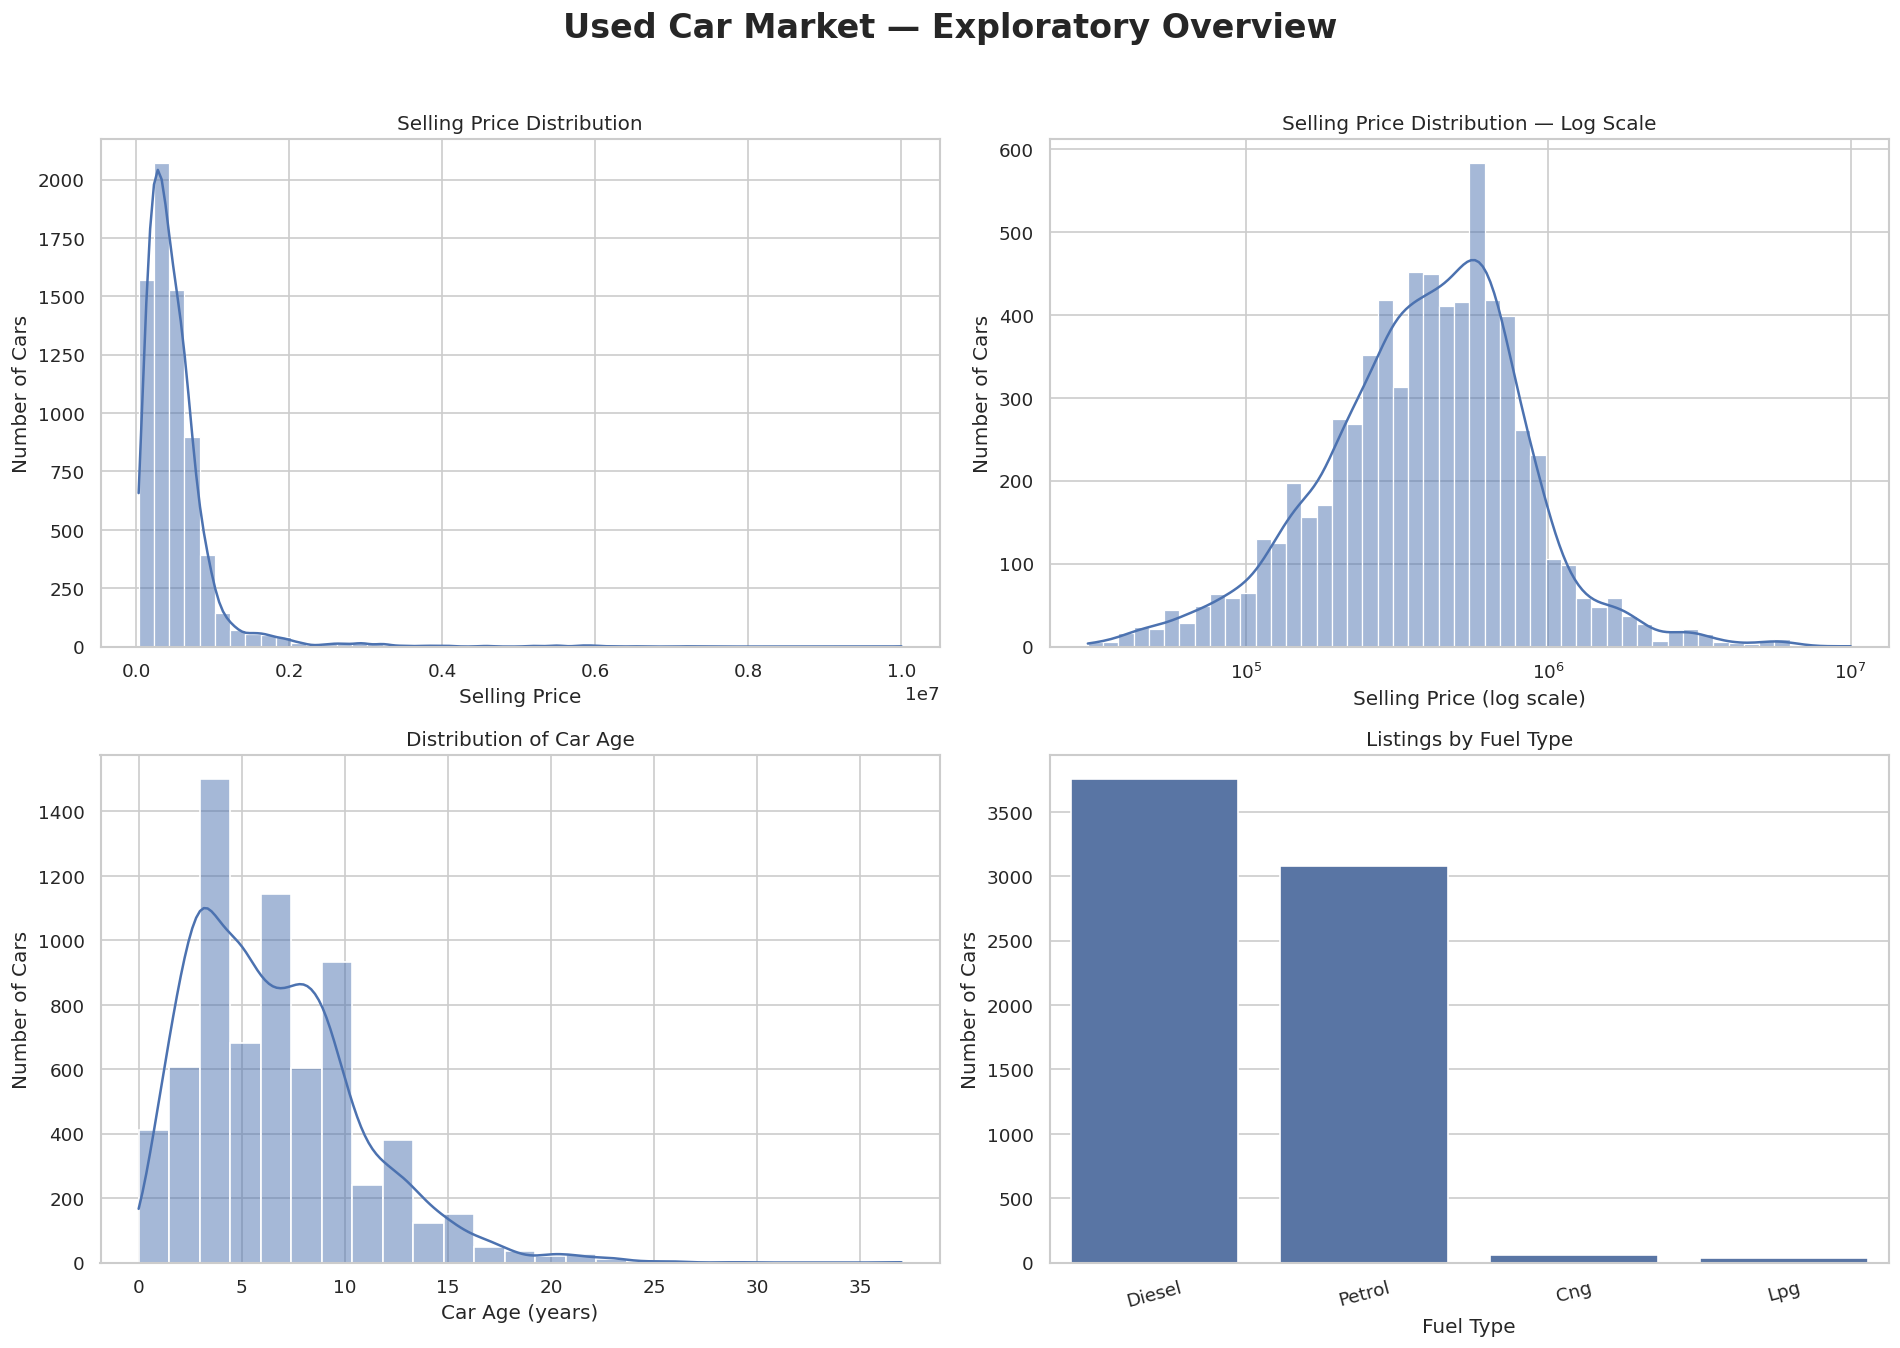

In [9]:

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.suptitle(
    "Used Car Market — Exploratory Overview",
    fontsize=20,
    fontweight="bold",
    y=1.02
)

# 1. Selling price distribution
sns.histplot(
    data=eda_df,
    x="selling_price",
    bins=50,
    kde=True,
    ax=axes[0, 0]
)
axes[0, 0].set_title("Selling Price Distribution")
axes[0, 0].set_xlabel("Selling Price")
axes[0, 0].set_ylabel("Number of Cars")

# 2. Selling price on a logarithmic scale
sns.histplot(
    data=eda_df,
    x="selling_price",
    bins=50,
    kde=True,
    log_scale=True,
    ax=axes[0, 1]
)
axes[0, 1].set_title("Selling Price Distribution — Log Scale")
axes[0, 1].set_xlabel("Selling Price (log scale)")
axes[0, 1].set_ylabel("Number of Cars")

# 3. Vehicle age distribution
sns.histplot(
    data=eda_df,
    x="car_age",
    bins=25,
    kde=True,
    ax=axes[1, 0]
)
axes[1, 0].set_title("Distribution of Car Age")
axes[1, 0].set_xlabel("Car Age (years)")
axes[1, 0].set_ylabel("Number of Cars")

# 4. Cars by fuel type
fuel_order = eda_df["fuel"].value_counts().index
sns.countplot(
    data=eda_df,
    x="fuel",
    order=fuel_order,
    ax=axes[1, 1]
)
axes[1, 1].set_title("Listings by Fuel Type")
axes[1, 1].set_xlabel("Fuel Type")
axes[1, 1].set_ylabel("Number of Cars")
axes[1, 1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()


Price by fuel type

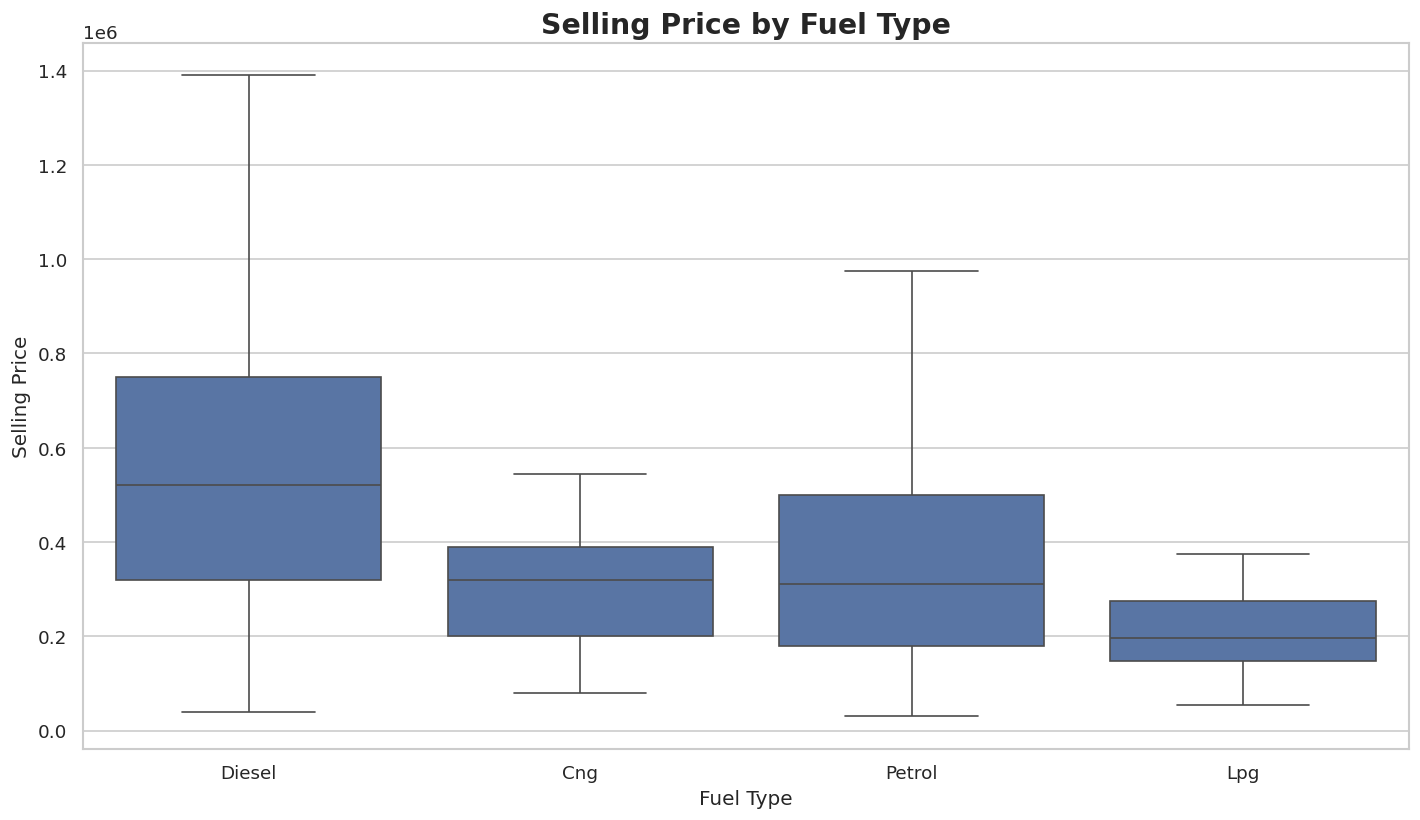

In [10]:

plt.figure(figsize=(12, 7))

fuel_order = (
    eda_df.groupby("fuel")["selling_price"]
    .median()
    .sort_values(ascending=False)
    .index
)

sns.boxplot(
    data=eda_df,
    x="fuel",
    y="selling_price",
    order=fuel_order,
    showfliers=False
)

plt.title("Selling Price by Fuel Type", fontsize=17, fontweight="bold")
plt.xlabel("Fuel Type")
plt.ylabel("Selling Price")
plt.tight_layout()
plt.show()


Price versus car age

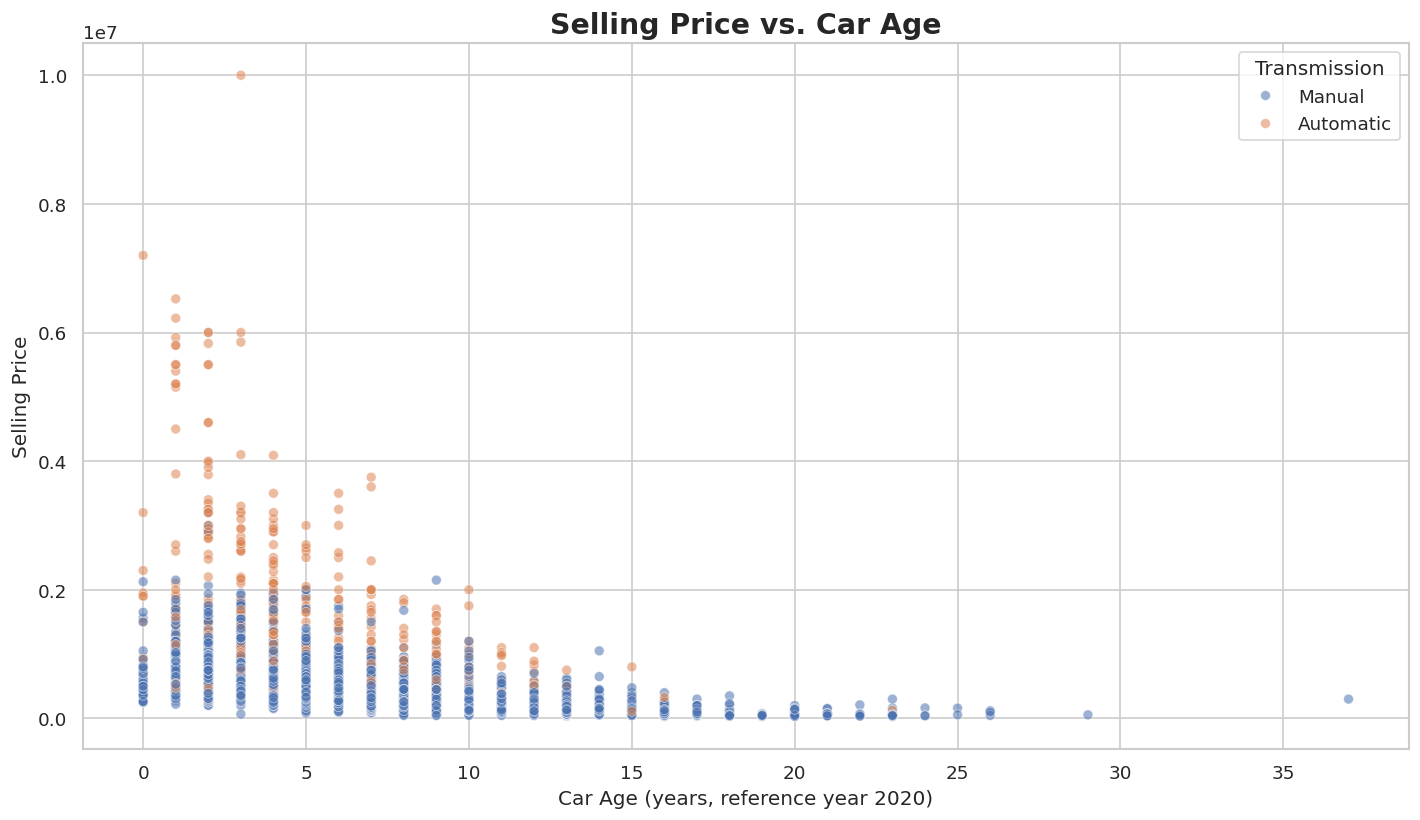

In [11]:

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=eda_df,
    x="car_age",
    y="selling_price",
    hue="transmission",
    alpha=0.55,
    s=35
)

plt.title("Selling Price vs. Car Age", fontsize=17, fontweight="bold")
plt.xlabel("Car Age (years, reference year 2020)")
plt.ylabel("Selling Price")
plt.legend(title="Transmission")
plt.tight_layout()
plt.show()


Mileage versus selling price

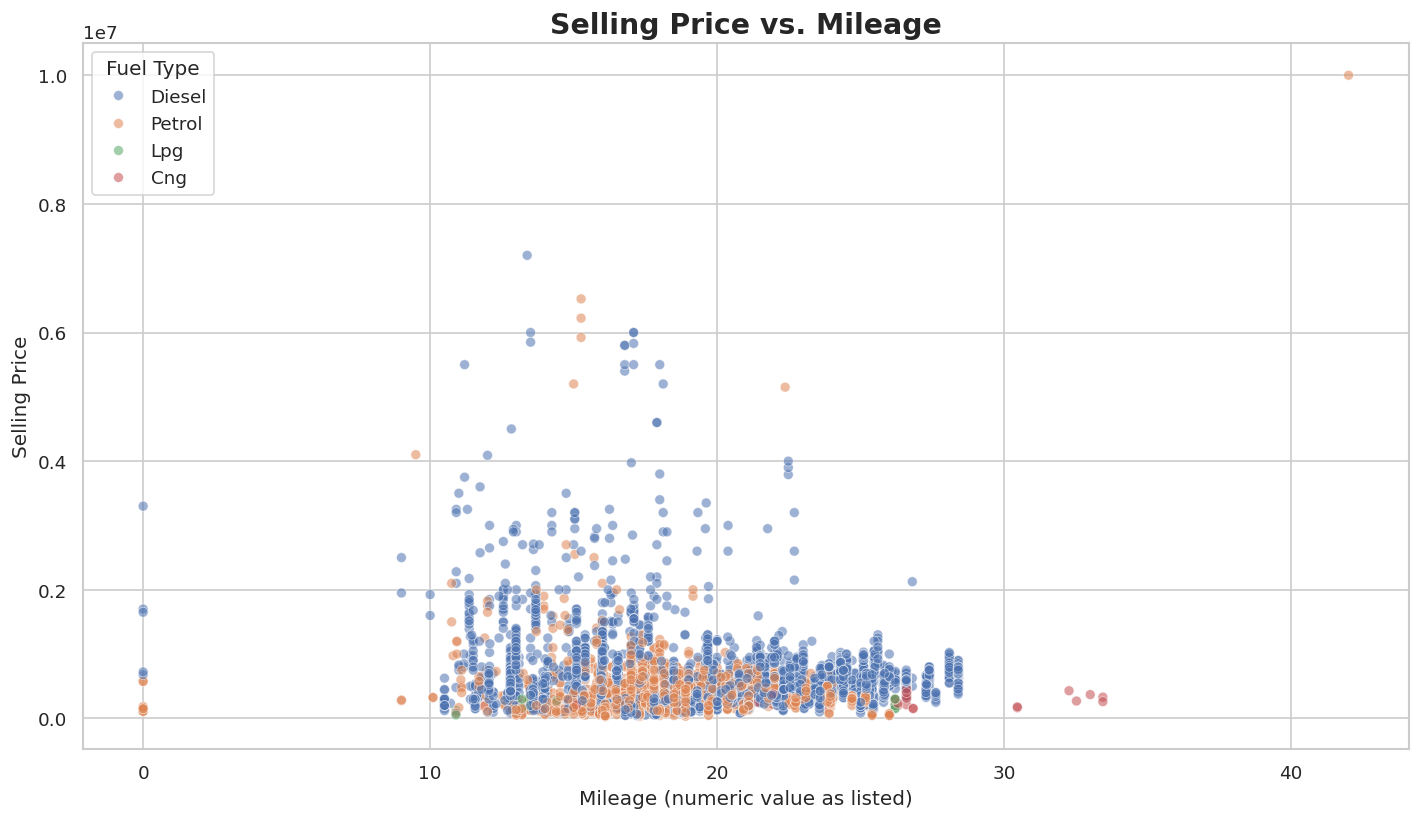

In [12]:

# Extract the numeric portion of mileage for exploratory analysis
eda_df["mileage_numeric"] = pd.to_numeric(
    eda_df["mileage"]
    .astype("string")
    .str.extract(r"([-+]?\d*\.?\d+)")[0],
    errors="coerce"
)

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=eda_df,
    x="mileage_numeric",
    y="selling_price",
    hue="fuel",
    alpha=0.55,
    s=35
)

plt.title("Selling Price vs. Mileage", fontsize=17, fontweight="bold")
plt.xlabel("Mileage (numeric value as listed)")
plt.ylabel("Selling Price")
plt.legend(title="Fuel Type")
plt.tight_layout()
plt.show()


Compare selling prices across transmission and ownership

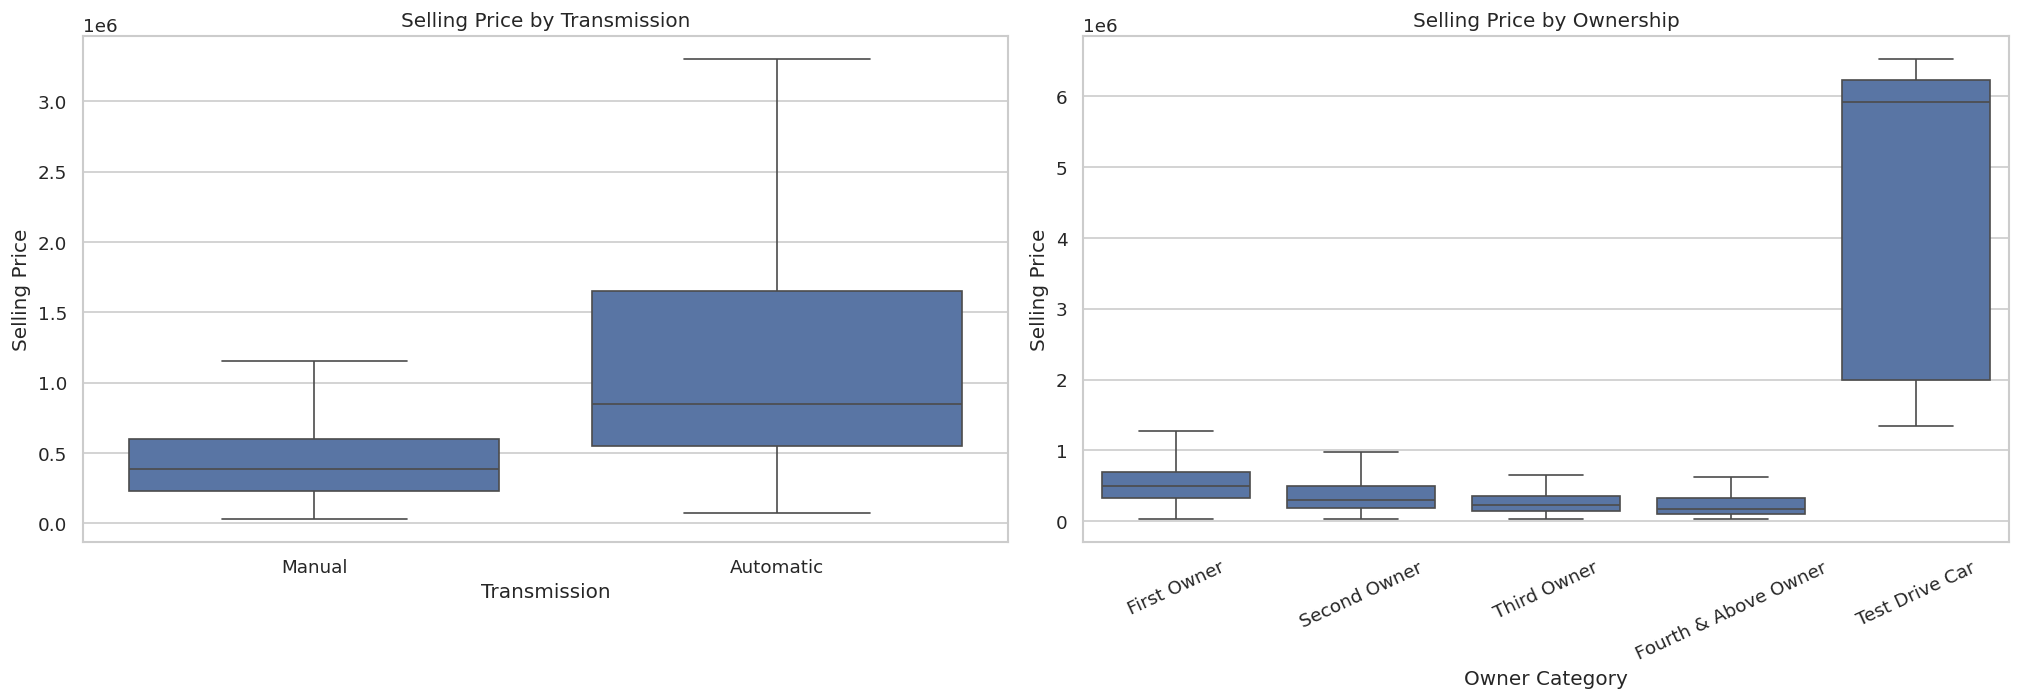

In [13]:

fig, axes = plt.subplots(1, 2, figsize=(17, 6))

sns.boxplot(
    data=eda_df,
    x="transmission",
    y="selling_price",
    showfliers=False,
    ax=axes[0]
)
axes[0].set_title("Selling Price by Transmission")
axes[0].set_xlabel("Transmission")
axes[0].set_ylabel("Selling Price")

owner_order = [
    owner for owner in [
        "First Owner",
        "Second Owner",
        "Third Owner",
        "Fourth & Above Owner",
        "Test Drive Car"
    ]
    if owner in eda_df["owner"].dropna().unique()
]

sns.boxplot(
    data=eda_df,
    x="owner",
    y="selling_price",
    order=owner_order,
    showfliers=False,
    ax=axes[1]
)
axes[1].set_title("Selling Price by Ownership")
axes[1].set_xlabel("Owner Category")
axes[1].set_ylabel("Selling Price")
axes[1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()


Top brands by listing count and median price

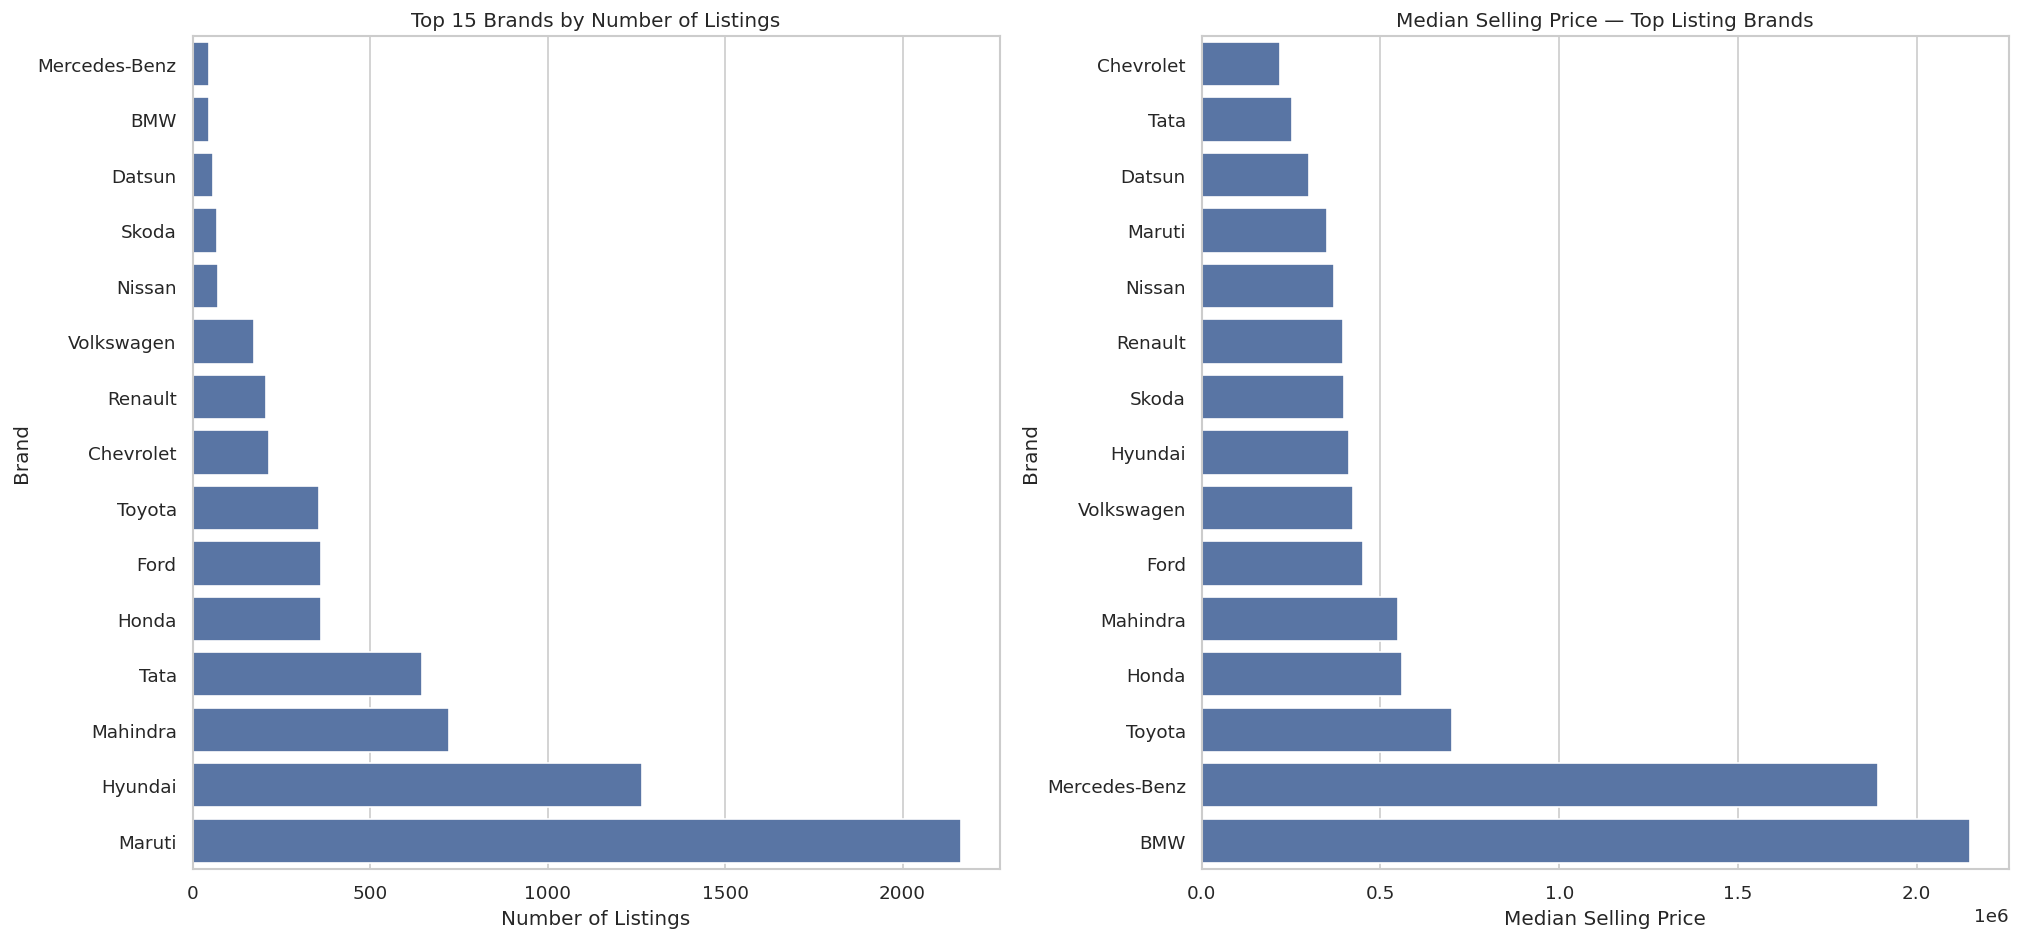

Top 15 brands summary:


,listing_count,median_price,mean_price
brand,,,
Maruti,2165,350000.0,387821.62
Hyundai,1267,412000.0,451051.64
Mahindra,723,550000.0,616549.06
Tata,647,252999.0,344393.98
Honda,362,560000.0,573563.91
Ford,361,450000.0,504376.69
Toyota,357,700000.0,889490.13
Chevrolet,216,220000.0,268349.63
Renault,206,395000.0,449694.14


In [14]:

brand_summary = (
    eda_df.groupby("brand")
    .agg(
        listing_count=("selling_price", "size"),
        median_price=("selling_price", "median"),
        mean_price=("selling_price", "mean")
    )
    .sort_values("listing_count", ascending=False)
)

top_brands = brand_summary.head(15).sort_values("listing_count")

fig, axes = plt.subplots(1, 2, figsize=(17, 8))

sns.barplot(
    data=top_brands.reset_index(),
    x="listing_count",
    y="brand",
    ax=axes[0]
)
axes[0].set_title("Top 15 Brands by Number of Listings")
axes[0].set_xlabel("Number of Listings")
axes[0].set_ylabel("Brand")

# Compare median price only among these high-volume brands
top_brand_names = brand_summary.head(15).index
median_prices = (
    eda_df[eda_df["brand"].isin(top_brand_names)]
    .groupby("brand")["selling_price"]
    .median()
    .sort_values()
    .reset_index()
)

sns.barplot(
    data=median_prices,
    x="selling_price",
    y="brand",
    ax=axes[1]
)
axes[1].set_title("Median Selling Price — Top Listing Brands")
axes[1].set_xlabel("Median Selling Price")
axes[1].set_ylabel("Brand")

plt.tight_layout()
plt.show()

print("Top 15 brands summary:")
display(brand_summary.head(15).round(2))


Correlation heatmap for the current numeric variables

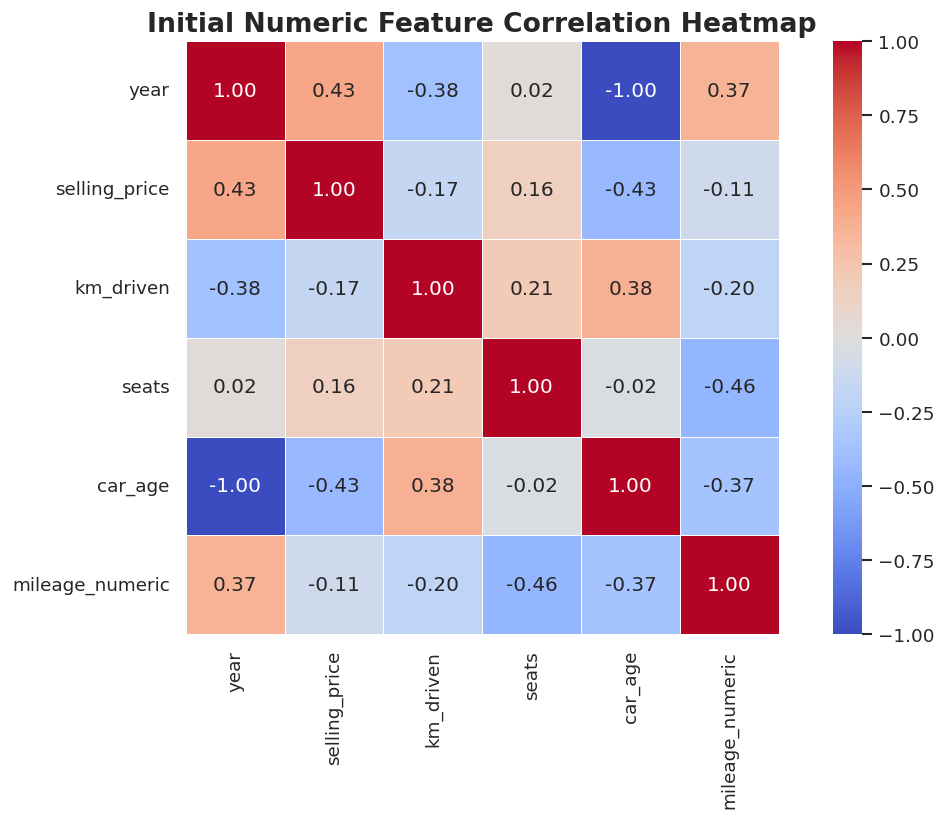

In [15]:

correlation_columns = [
    "year",
    "selling_price",
    "km_driven",
    "seats",
    "car_age",
    "mileage_numeric"
]

correlation_data = eda_df[correlation_columns].corr(numeric_only=True)

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_data,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
    square=True
)

plt.title("Initial Numeric Feature Correlation Heatmap", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()


EDA findings

In [16]:

print("========== EDA SUMMARY ==========")

print("\nSelling price:")
print("Median:", f"{eda_df['selling_price'].median():,.0f}")
print("Mean:", f"{eda_df['selling_price'].mean():,.0f}")
print("25th percentile:", f"{eda_df['selling_price'].quantile(0.25):,.0f}")
print("75th percentile:", f"{eda_df['selling_price'].quantile(0.75):,.0f}")

print("\nCar age:")
print("Median age:", f"{eda_df['car_age'].median():.1f} years")

print("\nFuel type listing counts:")
display(eda_df["fuel"].value_counts().to_frame("Count"))

print("\nMedian selling price by fuel type:")
display(
    eda_df.groupby("fuel")["selling_price"]
    .agg(["count", "median", "mean"])
    .sort_values("median", ascending=False)
    .round(2)
)

print("\nMedian selling price by transmission:")
display(
    eda_df.groupby("transmission")["selling_price"]
    .agg(["count", "median", "mean"])
    .round(2)
)

print("\nCorrelation with selling price:")
display(
    correlation_data["selling_price"]
    .drop("selling_price")
    .sort_values(key=abs, ascending=False)
    .to_frame("Correlation with Selling Price")
    .round(3)
)


========== EDA SUMMARY ==========

Selling price:
Median: 400,000
Mean: 517,271
25th percentile: 250,000
75th percentile: 633,500

Car age:
Median age: 6.0 years

Fuel type listing counts:


,Count
fuel,
Diesel,3755
Petrol,3077
Cng,56
Lpg,38



Median selling price by fuel type:


,count,median,mean
fuel,,,
Diesel,3755,520000.0,639727.77
Cng,56,320000.0,300499.95
Petrol,3077,310000.0,375688.97
Lpg,38,195500.0,200421.05



Median selling price by transmission:


,count,median,mean
transmission,,,
Automatic,584,850000.0,1309712.30
Manual,6342,385000.0,444299.07



Correlation with selling price:


,Correlation with Selling Price
car_age,-0.433
year,0.433
km_driven,-0.166
seats,0.158
mileage_numeric,-0.108


preprocessing and feature engineering

In [17]:

# Start from the original dataset and remove exact duplicate records
model_df = df.drop_duplicates().copy()

# Normalize text whitespace
text_columns = [
    "name", "fuel", "seller_type", "transmission",
    "owner", "mileage", "engine", "max_power", "torque"
]

for column in text_columns:
    model_df[column] = model_df[column].astype("string").str.strip()

# Standardize known categorical values consistently
fuel_map = {
    "diesel": "Diesel",
    "petrol": "Petrol",
    "cng": "CNG",
    "lpg": "LPG"
}

model_df["fuel"] = (
    model_df["fuel"].str.casefold().map(fuel_map).fillna(model_df["fuel"])
)

for column in ["seller_type", "transmission", "owner"]:
    model_df[column] = model_df[column].str.title()

# Correct common multiword manufacturer names during brand extraction
MULTIWORD_BRANDS = [
    "Mercedes-Benz",
    "Land Rover",
    "Force Motors",
    "Ashok Leyland",
    "Rolls-Royce"
]

def extract_brand(car_name):
    if pd.isna(car_name) or not str(car_name).strip():
        return np.nan

    car_name = str(car_name).strip()

    for brand in MULTIWORD_BRANDS:
        if car_name.casefold().startswith(brand.casefold()):
            return brand

    # Most remaining names begin with a single-word brand
    return car_name.split()[0]

model_df["brand"] = model_df["name"].apply(extract_brand)

# Calculate age using the dataset's reference year
REFERENCE_YEAR = 2020
model_df["car_age"] = REFERENCE_YEAR - model_df["year"]

print("Original rows:", len(df))
print("Rows after removing exact duplicates:", len(model_df))
print("Remaining exact duplicates:", model_df.duplicated().sum())
print("Unique brands:", model_df["brand"].nunique())

display(model_df[["name", "brand", "year", "car_age"]].head(10))


Original rows: 8128
Rows after removing exact duplicates: 6926
Remaining exact duplicates: 0
Unique brands: 32


,name,brand,year,car_age
0,Maruti Swift Dzire VDI,Maruti,2014,6
1,Skoda Rapid 1.5 TDI Ambition,Skoda,2014,6
2,Honda City 2017-2020 EXi,Honda,2006,14
3,Hyundai i20 Sportz Diesel,Hyundai,2010,10
4,Maruti Swift VXI BSIII,Maruti,2007,13
5,Hyundai Xcent 1.2 VTVT E Plus,Hyundai,2017,3
6,Maruti Wagon R LXI DUO BSIII,Maruti,2007,13
7,Maruti 800 DX BSII,Maruti,2001,19
8,Toyota Etios VXD,Toyota,2011,9
9,Ford Figo Diesel Celebration Edition,Ford,2013,7


Convert text specifications into numeric features

In [18]:

# Recreate model_df if the previous cleaning cell has not run
if "model_df" not in globals():
    model_df = df.drop_duplicates().copy()

    text_columns = [
        "name", "fuel", "seller_type", "transmission",
        "owner", "mileage", "engine", "max_power", "torque"
    ]

    for column in text_columns:
        model_df[column] = model_df[column].astype("string").str.strip()

    fuel_map = {
        "diesel": "Diesel",
        "petrol": "Petrol",
        "cng": "CNG",
        "lpg": "LPG"
    }

    model_df["fuel"] = (
        model_df["fuel"].str.casefold().map(fuel_map)
        .fillna(model_df["fuel"])
    )

    for column in ["seller_type", "transmission", "owner"]:
        model_df[column] = model_df[column].str.title()

    MULTIWORD_BRANDS = [
        "Mercedes-Benz", "Land Rover", "Force Motors",
        "Ashok Leyland", "Rolls-Royce"
    ]

    def extract_brand(car_name):
        if pd.isna(car_name) or not str(car_name).strip():
            return np.nan

        car_name = str(car_name).strip()

        for brand in MULTIWORD_BRANDS:
            if car_name.casefold().startswith(brand.casefold()):
                return brand

        return car_name.split()[0]

    model_df["brand"] = model_df["name"].apply(extract_brand)
    model_df["car_age"] = 2020 - model_df["year"]

# Extract numeric specifications
model_df["mileage_numeric"] = pd.to_numeric(
    model_df["mileage"].str.extract(r"([-+]?\d*\.?\d+)")[0],
    errors="coerce"
)

model_df["engine_cc"] = pd.to_numeric(
    model_df["engine"].str.extract(r"([-+]?\d*\.?\d+)")[0],
    errors="coerce"
)

model_df["max_power_bhp"] = pd.to_numeric(
    model_df["max_power"].str.extract(r"([-+]?\d*\.?\d+)")[0],
    errors="coerce"
)

# Preserve mileage units
mileage_text = model_df["mileage"].str.casefold()

model_df["mileage_unit"] = np.select(
    [
        mileage_text.str.contains("km/kg", na=False),
        mileage_text.str.contains("kmpl", na=False)
    ],
    ["km/kg", "kmpl"],
    default="Unknown"
)

model_df["seats"] = pd.to_numeric(
    model_df["seats"], errors="coerce"
)

# Review extraction results
new_numeric_columns = [
    "mileage_numeric", "engine_cc",
    "max_power_bhp", "seats"
]

print("Model dataset shape:", model_df.shape)

display(
    model_df[
        ["mileage", "mileage_numeric", "engine", "engine_cc",
         "max_power", "max_power_bhp", "mileage_unit"]
    ].head(15)
)

print("\nMissing values after extraction:")
display(
    model_df[new_numeric_columns].isna().sum()
    .to_frame("Missing Count")
    .assign(
        Missing_Percentage=lambda x:
        (x["Missing Count"] / len(model_df) * 100).round(2)
    )
)

print("\nZero or negative extracted values:")
for column in new_numeric_columns:
    count = int(
        (model_df[column].notna() & (model_df[column] <= 0)).sum()
    )
    print(f"{column}: {count}")


Model dataset shape: (6926, 19)


,mileage,mileage_numeric,engine,engine_cc,max_power,max_power_bhp,mileage_unit
0,23.4 kmpl,23.4,1248 CC,1248,74 bhp,74.0,kmpl
1,21.14 kmpl,21.14,1498 CC,1498,103.52 bhp,103.52,kmpl
2,17.7 kmpl,17.7,1497 CC,1497,78 bhp,78.0,kmpl
3,23.0 kmpl,23.0,1396 CC,1396,90 bhp,90.0,kmpl
4,16.1 kmpl,16.1,1298 CC,1298,88.2 bhp,88.2,kmpl
5,20.14 kmpl,20.14,1197 CC,1197,81.86 bhp,81.86,kmpl
6,17.3 km/kg,17.3,1061 CC,1061,57.5 bhp,57.5,km/kg
7,16.1 kmpl,16.1,796 CC,796,37 bhp,37.0,kmpl
8,23.59 kmpl,23.59,1364 CC,1364,67.1 bhp,67.1,kmpl
9,20.0 kmpl,20.0,1399 CC,1399,68.1 bhp,68.1,kmpl



Missing values after extraction:


,Missing Count,Missing_Percentage
mileage_numeric,208,3.00
engine_cc,208,3.00
max_power_bhp,206,2.97
seats,208,3.00



Zero or negative extracted values:
mileage_numeric: 15
engine_cc: 0
max_power_bhp: 3
seats: 0


Improve the numerical correlation heatmap

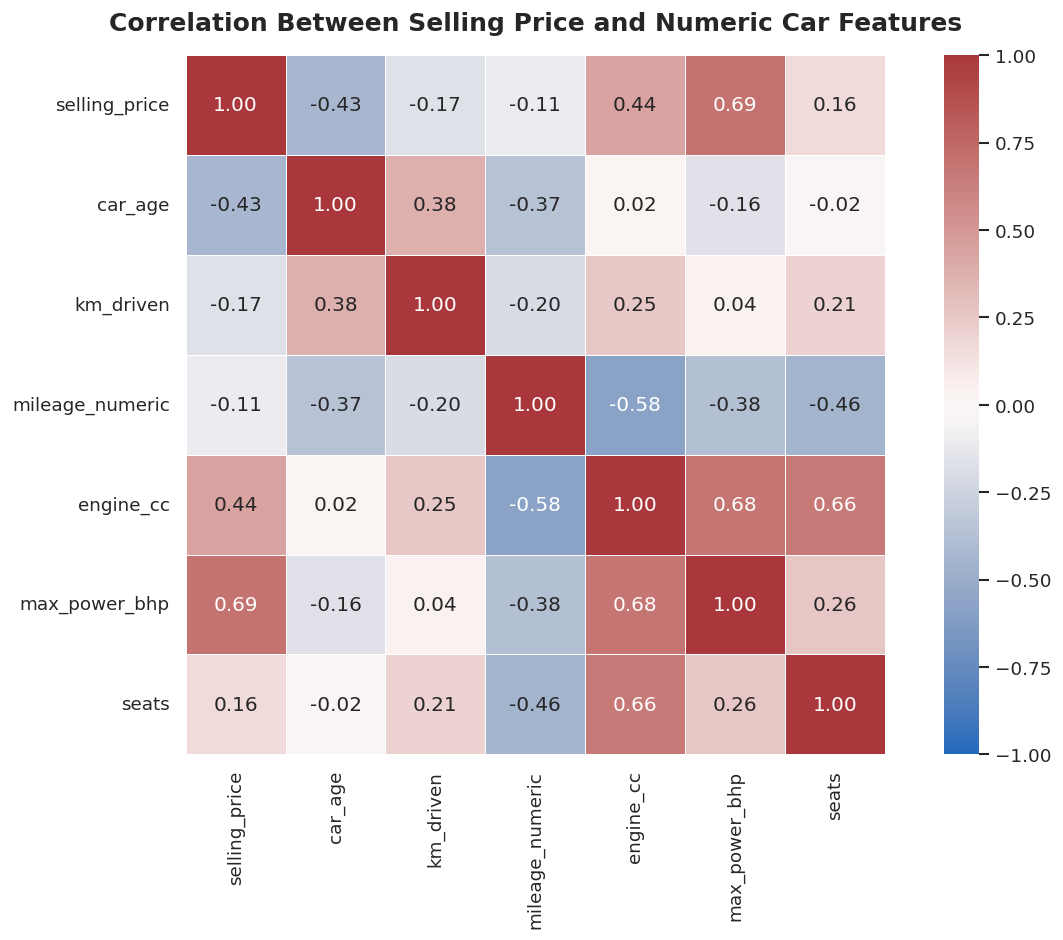

Correlation with selling price:


,Correlation
max_power_bhp,0.692
engine_cc,0.443
car_age,-0.433
km_driven,-0.166
seats,0.158
mileage_numeric,-0.108


In [19]:

heatmap_columns = [
    "selling_price",
    "car_age",
    "km_driven",
    "mileage_numeric",
    "engine_cc",
    "max_power_bhp",
    "seats"
]

corr_matrix = model_df[heatmap_columns].corr(numeric_only=True)

plt.figure(figsize=(11, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.6,
    square=True
)

plt.title(
    "Correlation Between Selling Price and Numeric Car Features",
    fontsize=15,
    fontweight="bold",
    pad=15
)
plt.tight_layout()
plt.show()

print("Correlation with selling price:")
display(
    corr_matrix["selling_price"]
    .drop("selling_price")
    .sort_values(key=abs, ascending=False)
    .to_frame("Correlation")
    .round(3)
)


Final modeling data-quality check

In [20]:

print("Modeling dataset shape:", model_df.shape)

print("\nMissing values in important fields:")
display(
    model_df[
        [
            "selling_price", "brand", "car_age", "km_driven",
            "mileage_numeric", "engine_cc", "max_power_bhp", "seats"
        ]
    ].isna().sum().to_frame("Missing Count")
)

print("\nTarget summary:")
display(model_df["selling_price"].describe().to_frame("Selling Price"))

print("\nCategorical feature values:")
for column in [
    "fuel", "seller_type", "transmission", "owner", "mileage_unit"
]:
    print(f"\n{column}:")
    print(model_df[column].value_counts(dropna=False))


Modeling dataset shape: (6926, 19)

Missing values in important fields:


,Missing Count
selling_price,0
brand,0
car_age,0
km_driven,0
mileage_numeric,208
engine_cc,208
max_power_bhp,206
seats,208



Target summary:


,Selling Price
count,6.926000e+03
mean,5.172707e+05
std,5.197670e+05
min,2.999900e+04
25%,2.500000e+05
50%,4.000000e+05
75%,6.335000e+05
max,1.000000e+07



Categorical feature values:

fuel:
fuel
Diesel    3755
Petrol    3077
CNG         56
LPG         38
Name: count, dtype: int64

seller_type:
seller_type
Individual          6218
Dealer               681
Trustmark Dealer      27
Name: count, dtype: Int64

transmission:
transmission
Manual       6342
Automatic     584
Name: count, dtype: Int64

owner:
owner
First Owner             4242
Second Owner            1974
Third Owner              536
Fourth & Above Owner     169
Test Drive Car             5
Name: count, dtype: Int64

mileage_unit:
mileage_unit
kmpl       6631
Unknown     208
km/kg        87
Name: count, dtype: int64


Train/test split

In [21]:

from sklearn.model_selection import train_test_split

target_column = "selling_price"

numeric_features = [
    "car_age",
    "km_driven",
    "mileage_numeric",
    "engine_cc",
    "max_power_bhp",
    "seats"
]

categorical_features = [
    "brand",
    "fuel",
    "seller_type",
    "transmission",
    "owner",
    "mileage_unit"
]

feature_columns = numeric_features + categorical_features

X = model_df[feature_columns].copy()
y = model_df[target_column].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training feature matrix:", X_train.shape)
print("Test feature matrix:", X_test.shape)
print("Training target:", y_train.shape)
print("Test target:", y_test.shape)

print("\nTraining target median:", round(y_train.median(), 2))
print("Test target median:", round(y_test.median(), 2))


Training feature matrix: (5540, 12)
Test feature matrix: (1386, 12)
Training target: (5540,)
Test target: (1386,)

Training target median: 400000.0
Test target median: 409999.0


Build preprocessing and baseline models

In [22]:

# CELL 23: Preprocessing Pipeline and Baseline Model Comparison

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Define preprocessing for numeric and categorical features
numeric_features = [
    "car_age",
    "km_driven",
    "mileage_numeric",
    "engine_cc",
    "max_power_bhp",
    "seats"
]

categorical_features = [
    "brand",
    "fuel",
    "seller_type",
    "transmission",
    "owner",
    "mileage_unit"
]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# 2. Define models
models = {
    "Median Baseline": DummyRegressor(strategy="median"),

    "Linear Regression": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1,
        min_samples_leaf=2
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1,
        min_samples_leaf=2
    )
}

# 3. Train each model and evaluate on the test set
results = []
trained_models = {}

for model_name, model in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

    trained_models[model_name] = pipeline

# 4. Display model comparison
results_df = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)

print("BASELINE MODEL COMPARISON")
display(results_df.round(3))

print("\nBest model by test RMSE:", results_df.iloc[0]["Model"])


BASELINE MODEL COMPARISON


,Model,MAE,RMSE,R2 Score
0,Random Forest,71620.889,121710.675,0.932
1,Extra Trees,75776.484,154414.171,0.891
2,Linear Regression,133059.847,261886.824,0.687
3,Median Baseline,259546.730,478963.265,-0.046



Best model by test RMSE: Random Forest


Cross-validation for Random Forest

In [23]:

# CELL 24: 5-Fold Cross-Validation for Random Forest

from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
import pandas as pd
import numpy as np

# Create a fresh pipeline with the same preprocessing approach
rf_cv_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        min_samples_leaf=2,
        n_jobs=-1
    ))
])

# Five-fold cross-validation on training data only
cv_strategy = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = cross_validate(
    rf_cv_pipeline,
    X_train,
    y_train,
    cv=cv_strategy,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error",
        "R2": "r2"
    },
    return_train_score=True,
    n_jobs=1
)

# Convert negative error scores into positive values
cv_summary = pd.DataFrame({
    "Fold": np.arange(1, 6),
    "Validation MAE": -cv_results["test_MAE"],
    "Validation RMSE": -cv_results["test_RMSE"],
    "Validation R2": cv_results["test_R2"],
    "Training R2": cv_results["train_R2"]
})

print("RANDOM FOREST — 5-FOLD CROSS-VALIDATION")
display(cv_summary.round(3))

print("\nCROSS-VALIDATION SUMMARY")
display(pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2"],
    "Mean": [
        (-cv_results["test_MAE"]).mean(),
        (-cv_results["test_RMSE"]).mean(),
        cv_results["test_R2"].mean()
    ],
    "Standard Deviation": [
        (-cv_results["test_MAE"]).std(),
        (-cv_results["test_RMSE"]).std(),
        cv_results["test_R2"].std()
    ]
}).round(3))


RANDOM FOREST — 5-FOLD CROSS-VALIDATION


,Fold,Validation MAE,Validation RMSE,Validation R2,Training R2
0,1,87760.350,195547.304,0.901,0.958
1,2,81416.612,166356.720,0.917,0.961
2,3,82632.997,160747.073,0.888,0.967
3,4,79448.000,157005.553,0.871,0.966
4,5,82221.416,230537.107,0.804,0.973



CROSS-VALIDATION SUMMARY


,Metric,Mean,Standard Deviation
0,MAE,82695.875,2759.100
1,RMSE,182038.751,27786.666
2,R2,0.876,0.039


Hyperparameter tuning with GridSearchCV

In [24]:

# CELL 25: Random Forest Hyperparameter Tuning with GridSearchCV

import pandas as pd
import numpy as np

from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, KFold

# 1. Build a fresh pipeline
rf_tuning_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        random_state=42,
        n_jobs=1
    ))
])

# 2. Define the hyperparameter search space
param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 20],
    "model__min_samples_split": [2, 5],
    "model__min_samples_leaf": [1, 2, 4]
}

# Total: 2 × 2 × 2 × 3 = 24 combinations
# With 5 folds: 120 model fits

cv_strategy = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=rf_tuning_pipeline,
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=cv_strategy,
    n_jobs=-1,
    verbose=2,
    return_train_score=True,
    refit=True
)

print("Starting GridSearchCV...")
print("Parameter combinations:", len(list(
    __import__("sklearn").model_selection.ParameterGrid(param_grid)
)))
print("Cross-validation folds:", 5)
print("Total CV fits: 120")
print("Optimization metric: RMSE (lower is better)")
print("-" * 65)

# 3. Run tuning on training data only
grid_search.fit(X_train, y_train)

print("\n" + "=" * 65)
print("GRID SEARCH COMPLETE")
print("=" * 65)

print("\nBest cross-validation RMSE:",
      round(-grid_search.best_score_, 2))

print("\nBest hyperparameters:")
for parameter, value in grid_search.best_params_.items():
    print(f"{parameter}: {value}")

# 4. Show the top 10 configurations
cv_results_df = pd.DataFrame(grid_search.cv_results_)

cv_results_df["Mean CV RMSE"] = -cv_results_df["mean_test_score"]
cv_results_df["Std CV RMSE"] = cv_results_df["std_test_score"]
cv_results_df["Mean Training RMSE"] = -cv_results_df["mean_train_score"]

top_results = cv_results_df.sort_values(
    "Mean CV RMSE",
    ascending=True
)[[
    "rank_test_score",
    "params",
    "Mean CV RMSE",
    "Std CV RMSE",
    "Mean Training RMSE",
    "mean_fit_time"
]].head(10).reset_index(drop=True)

display(top_results.round(3))


Starting GridSearchCV...
Parameter combinations: 24
Cross-validation folds: 5
Total CV fits: 120
Optimization metric: RMSE (lower is better)
-----------------------------------------------------------------
Fitting 5 folds for each of 24 candidates, totalling 120 fits

GRID SEARCH COMPLETE

Best cross-validation RMSE: 176971.5

Best hyperparameters:
model__max_depth: None
model__min_samples_leaf: 1
model__min_samples_split: 5
model__n_estimators: 200


,rank_test_score,params,Mean CV RMSE,Std CV RMSE,Mean Training RMSE,mean_fit_time
0,1,"{'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__min_samples_split': 5, 'model__...",176971.496,26524.333,83520.723,21.899
1,2,"{'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__min_samples_split': 5, 'model__...",177048.951,26480.905,85338.727,11.081
2,3,"{'model__max_depth': 20, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__n_...",177088.603,26094.067,67990.398,28.535
3,4,"{'model__max_depth': 20, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__n_...",177135.264,25933.930,69589.494,14.402
4,5,"{'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__...",177237.081,26492.279,69083.543,15.357
5,6,"{'model__max_depth': 20, 'model__min_samples_leaf': 1, 'model__min_samples_split': 5, 'model__n_...",177523.647,27402.611,85644.884,11.063
6,7,"{'model__max_depth': 20, 'model__min_samples_leaf': 1, 'model__min_samples_split': 5, 'model__n_...",177660.763,26991.751,83830.570,21.544
7,8,"{'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__...",177700.991,26490.140,67679.261,29.473
8,9,"{'model__max_depth': None, 'model__min_samples_leaf': 2, 'model__min_samples_split': 5, 'model__...",180827.551,27542.134,104465.212,10.148
9,10,"{'model__max_depth': 20, 'model__min_samples_leaf': 2, 'model__min_samples_split': 2, 'model__n_...",181145.688,27814.952,100062.681,10.593


Inspect the selected model and cross-validation results

In [25]:

# CELL 26: Inspect Best Parameters and CV Results

print("Best parameters:")
for param, value in grid_search.best_params_.items():
    print(f"{param}: {value}")

print(f"\nBest mean 5-fold CV RMSE: {-grid_search.best_score_:,.2f}")

cv_results = pd.DataFrame(grid_search.cv_results_).copy()
cv_results["Mean CV RMSE"] = -cv_results["mean_test_score"]
cv_results["Std CV RMSE"] = cv_results["std_test_score"]

print("\nTop 5 configurations:")
display(
    cv_results.sort_values("rank_test_score")[
        ["rank_test_score", "params", "Mean CV RMSE", "Std CV RMSE"]
    ].head(5).round(3)
)

print("\nSelected estimator has been refitted on all training data.")


Best parameters:
model__max_depth: None
model__min_samples_leaf: 1
model__min_samples_split: 5
model__n_estimators: 200

Best mean 5-fold CV RMSE: 176,971.50

Top 5 configurations:


,rank_test_score,params,Mean CV RMSE,Std CV RMSE
3,1,"{'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__min_samples_split': 5, 'model__...",176971.496,26524.333
2,2,"{'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__min_samples_split': 5, 'model__...",177048.951,26480.905
13,3,"{'model__max_depth': 20, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__n_...",177088.603,26094.067
12,4,"{'model__max_depth': 20, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__n_...",177135.264,25933.930
0,5,"{'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__...",177237.081,26492.279



Selected estimator has been refitted on all training data.


Final test evaluation

In [26]:

# CELL 27: Evaluate Original vs Tuned Random Forest

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Predictions on the untouched test set
original_rf = trained_models["Random Forest"]
tuned_rf = grid_search.best_estimator_

y_pred_original = original_rf.predict(X_test)
y_pred_tuned = tuned_rf.predict(X_test)

def regression_metrics(y_true, y_pred, model_name):
    return {
        "Model": model_name,
        "MAE (Rs.)": mean_absolute_error(y_true, y_pred),
        "RMSE (Rs.)": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2 Score": r2_score(y_true, y_pred)
    }

final_comparison = pd.DataFrame([
    regression_metrics(y_test, y_pred_original, "Original Random Forest"),
    regression_metrics(y_test, y_pred_tuned, "Tuned Random Forest")
])

display(final_comparison.round(3))

print("Best tuned CV RMSE:", f"Rs. {-grid_search.best_score_:,.2f}")
print("Note: choose based on CV and test performance together.")


,Model,MAE (Rs.),RMSE (Rs.),R2 Score
0,Original Random Forest,71620.889,121710.675,0.932
1,Tuned Random Forest,71706.406,125768.287,0.928


Best tuned CV RMSE: Rs. 176,971.50
Note: choose based on CV and test performance together.


Actual vs. predicted prices

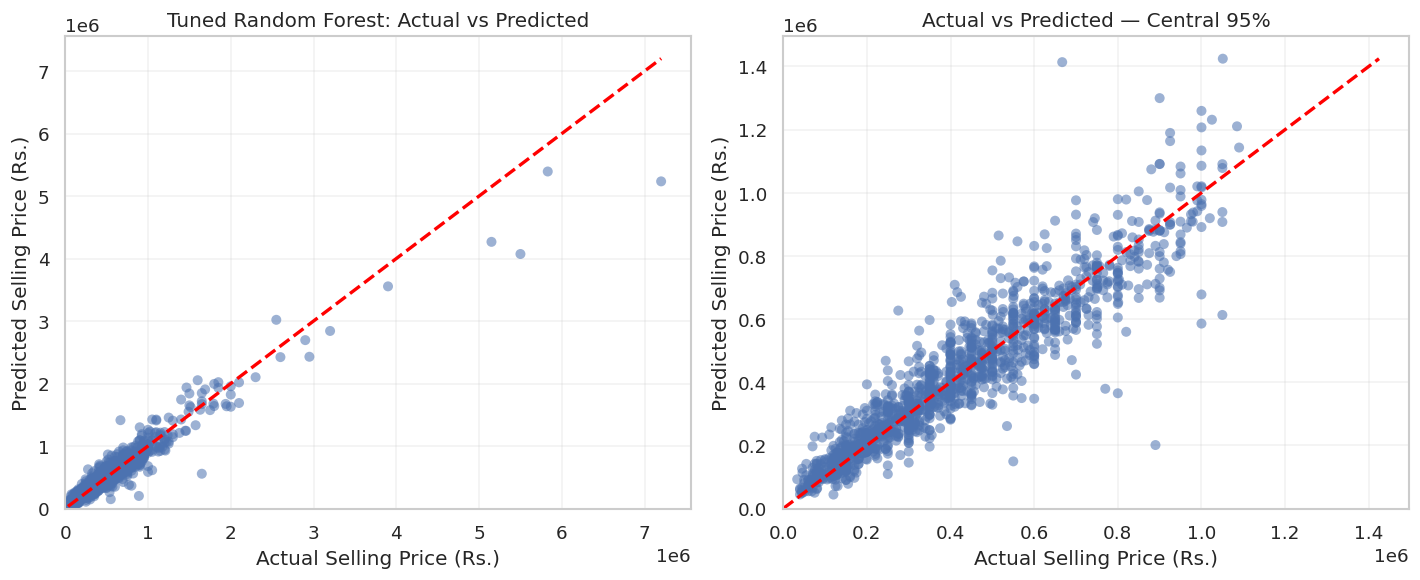

In [37]:
# CELL 28: Actual vs Predicted Selling Prices (Side-by-Side)

import matplotlib.pyplot as plt
import numpy as np

# Create a figure with 1 row and 2 columns
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# --- Subplot 1: Full Range ---
lower = min(float(np.min(y_test)), float(np.min(y_pred_tuned)))
upper = max(float(np.max(y_test)), float(np.max(y_pred_tuned)))

axes[0].scatter(y_test, y_pred_tuned, alpha=0.55, edgecolors="none")
axes[0].plot([lower, upper], [lower, upper], linestyle="--", linewidth=2, color="red")
axes[0].set_xlabel("Actual Selling Price (Rs.)")
axes[0].set_ylabel("Predicted Selling Price (Rs.)")
axes[0].set_title("Tuned Random Forest: Actual vs Predicted")
axes[0].set_xlim(left=0)
axes[0].set_ylim(bottom=0)
axes[0].grid(alpha=0.25)

# --- Subplot 2: Central 95% Zoom ---
actual_95 = np.quantile(y_test, 0.95)
mask = np.asarray(y_test) <= actual_95

y_test_masked = np.asarray(y_test)[mask]
y_pred_masked = np.asarray(y_pred_tuned)[mask]

zoom_upper = max(float(np.max(y_test_masked)), float(np.max(y_pred_masked)))

axes[1].scatter(y_test_masked, y_pred_masked, alpha=0.55, edgecolors="none")
axes[1].plot([0, zoom_upper], [0, zoom_upper], linestyle="--", linewidth=2, color="red")
axes[1].set_xlabel("Actual Selling Price (Rs.)")
axes[1].set_ylabel("Predicted Selling Price (Rs.)")
axes[1].set_title("Actual vs Predicted — Central 95%")
axes[1].set_xlim(left=0)
axes[1].set_ylim(bottom=0)
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

Residual analysis and largest errors

Residual = actual price − predicted price. Positive residuals mean the model underpredicted the price; negative residuals mean it overpredicted.

Residual summary:


,Residual (Actual - Predicted),Absolute Error,Absolute Error (%)
count,1386.00,1386.00,1386.00
mean,988.91,71706.41,17.74
std,125809.79,103361.32,19.90
min,-746621.79,15.62,0.01
25%,-48331.17,20077.82,5.64
50%,-5659.99,46330.42,12.34
75%,44034.76,88895.01,22.39
max,1964897.41,1964897.41,203.28


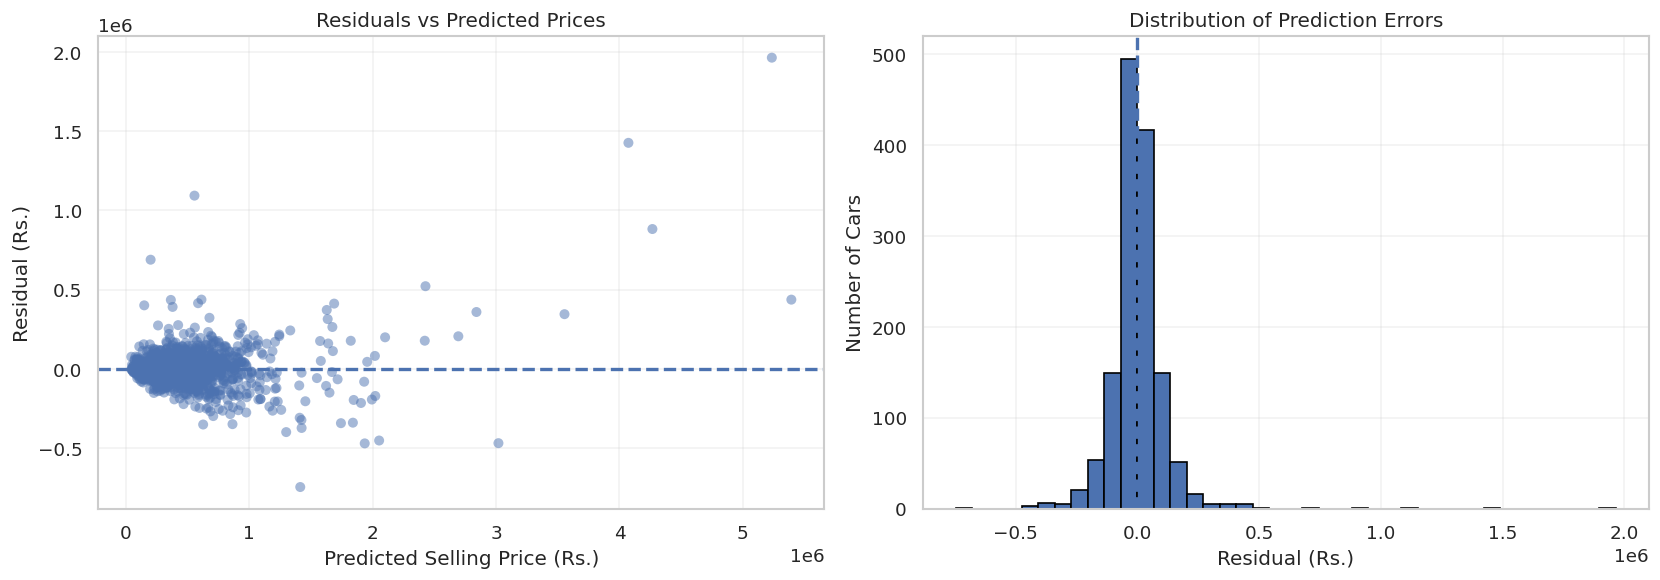

10 largest prediction errors:


,Actual Price,Predicted Price,Residual (Actual - Predicted),Absolute Error,Absolute Error (%)
2938,7200000,5235102.59,1964897.41,1964897.41,27.29
7930,5500000,4072922.96,1427077.04,1427077.04,25.95
2137,1650000,556337.24,1093662.76,1093662.76,66.28
132,5150000,4267274.82,882725.18,882725.18,17.14
4592,667000,1413621.79,-746621.79,746621.79,111.94
6598,890000,200997.70,689002.30,689002.30,77.42
1990,2950000,2428304.48,521695.52,521695.52,17.68
4704,1465000,1936048.21,-471048.21,471048.21,32.15
156,2550000,3019573.43,-469573.43,469573.43,18.41
4380,1600000,2052877.46,-452877.46,452877.46,28.30


In [30]:

# CELL 29: Residual Analysis and Largest Prediction Errors

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

actual = np.asarray(y_test)
predicted = np.asarray(y_pred_tuned)
residuals = actual - predicted

residual_df = pd.DataFrame({
    "Actual Price": actual,
    "Predicted Price": predicted,
    "Residual (Actual - Predicted)": residuals,
    "Absolute Error": np.abs(residuals),
    "Absolute Error (%)": np.abs(residuals) / np.maximum(np.abs(actual), 1) * 100
}, index=getattr(y_test, "index", None))

print("Residual summary:")
display(residual_df[
    ["Residual (Actual - Predicted)", "Absolute Error", "Absolute Error (%)"]
].describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(predicted, residuals, alpha=0.5, edgecolors="none")
axes[0].axhline(0, linestyle="--", linewidth=2)
axes[0].set_xlabel("Predicted Selling Price (Rs.)")
axes[0].set_ylabel("Residual (Rs.)")
axes[0].set_title("Residuals vs Predicted Prices")
axes[0].grid(alpha=0.25)

axes[1].hist(residuals, bins=40, edgecolor="black")
axes[1].axvline(0, linestyle="--", linewidth=2)
axes[1].set_xlabel("Residual (Rs.)")
axes[1].set_ylabel("Number of Cars")
axes[1].set_title("Distribution of Prediction Errors")
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

print("10 largest prediction errors:")
display(
    residual_df.sort_values("Absolute Error", ascending=False).head(10).round(2)
)


Feature importance

Top 20 most important encoded features:


,Feature,Importance
0,num__max_power_bhp,0.60558
1,num__car_age,0.22981
2,num__km_driven,0.04641
3,num__mileage_numeric,0.03812
4,num__engine_cc,0.02245
5,num__seats,0.00712
6,cat__brand_Mercedes-Benz,0.00577
7,cat__brand_Toyota,0.00546
8,cat__brand_Tata,0.00413
9,cat__brand_Land Rover,0.00409


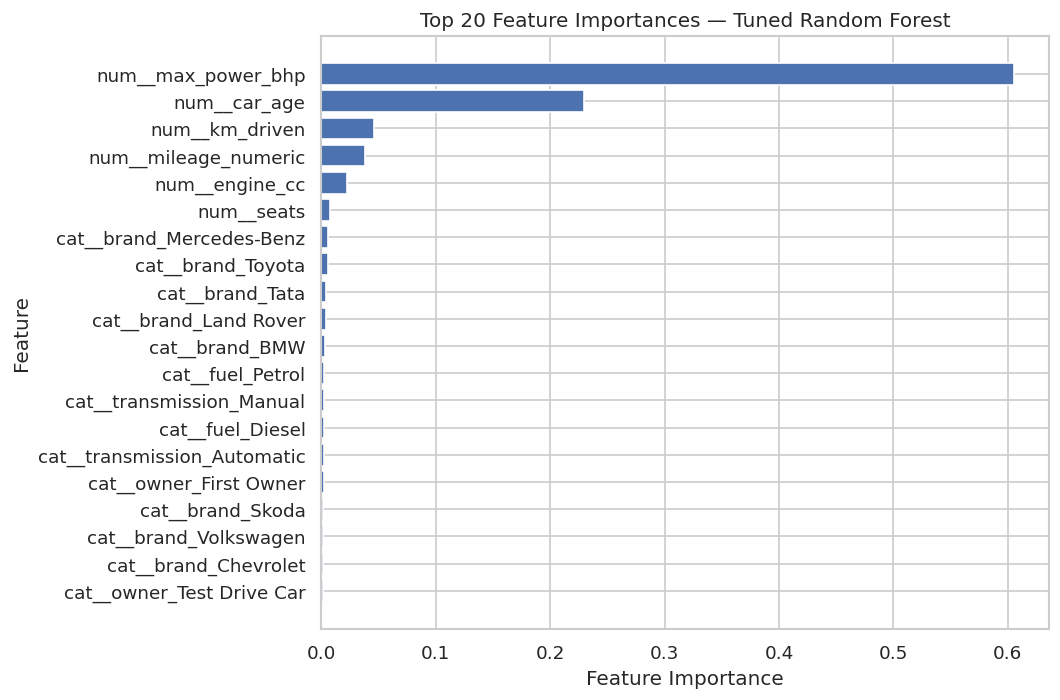

Importance aggregated by preprocessing group:


,Feature Group,Total Importance
0,num,0.94948
1,cat,0.05052


In [35]:

# CELL 30: Tuned Random Forest Feature Importance

import pandas as pd
import matplotlib.pyplot as plt

best_preprocessor = tuned_rf.named_steps["preprocessor"]
best_model = tuned_rf.named_steps["model"]

feature_names = best_preprocessor.get_feature_names_out()
importances = best_model.feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False).reset_index(drop=True)

print("Top 20 most important encoded features:")
display(importance_df.head(20).round(5))

top_features = importance_df.head(20).sort_values("Importance")

plt.figure(figsize=(9, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 20 Feature Importances — Tuned Random Forest")
plt.tight_layout()
plt.show()

# Aggregate importance by original feature group
group_importance = importance_df.copy()
group_importance["Feature Group"] = group_importance["Feature"].str.split("__").str[0]
group_importance = (
    group_importance.groupby("Feature Group")["Importance"]
    .sum()
    .sort_values(ascending=False)
    .rename("Total Importance")
    .reset_index()
)

print("Importance aggregated by preprocessing group:")
display(group_importance.round(5))


Save the final model pipeline

In [36]:

# CELL 31: Save the Final Tuned Model

import joblib
import json
from pathlib import Path

model_path = Path("car_price_prediction_model.joblib")
metadata_path = Path("car_price_model_metadata.json")

# Save the complete fitted preprocessing + model pipeline
joblib.dump(tuned_rf, model_path)

metadata = {
    "project": "Car Price Prediction",
    "model": "RandomForestRegressor",
    "best_parameters": grid_search.best_params_,
    "best_5_fold_cv_rmse": float(-grid_search.best_score_),
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "target": "selling_price",
    "random_state": 42
}

with open(metadata_path, "w") as file:
    json.dump(metadata, file, indent=4, default=str)

print("Model saved:", model_path.resolve())
print("Metadata saved:", metadata_path.resolve())
print(f"Best CV RMSE: Rs. {-grid_search.best_score_:,.2f}")

# Download both files from Google Colab
try:
    from google.colab import files
    files.download(str(model_path))
    files.download(str(metadata_path))
except ImportError:
    print("Not running in Google Colab; files are saved in the current directory.")


Model saved: /content/car_price_prediction_model.joblib
Metadata saved: /content/car_price_model_metadata.json
Best CV RMSE: Rs. 176,971.50


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>